# W12A · 변수변환 R 실습

먼저 결과를 예상하고 코드 본문을 수정한 뒤 계산값과 그림을 비교합니다. 수정하기 전과 뒤에 결과가 달라진 이유를 한 문장으로 적으세요. 실습 A와 B는 독립 실행됩니다.

## B1 · 원척도 직선 점검

원자료 15개를 확인합니다. 마지막 적합값의 부호와 표준화 잔차의 처음·중간·마지막 부호를 먼저 예상하세요. 원척도 직선의 계수 옆에 단위를 적습니다.

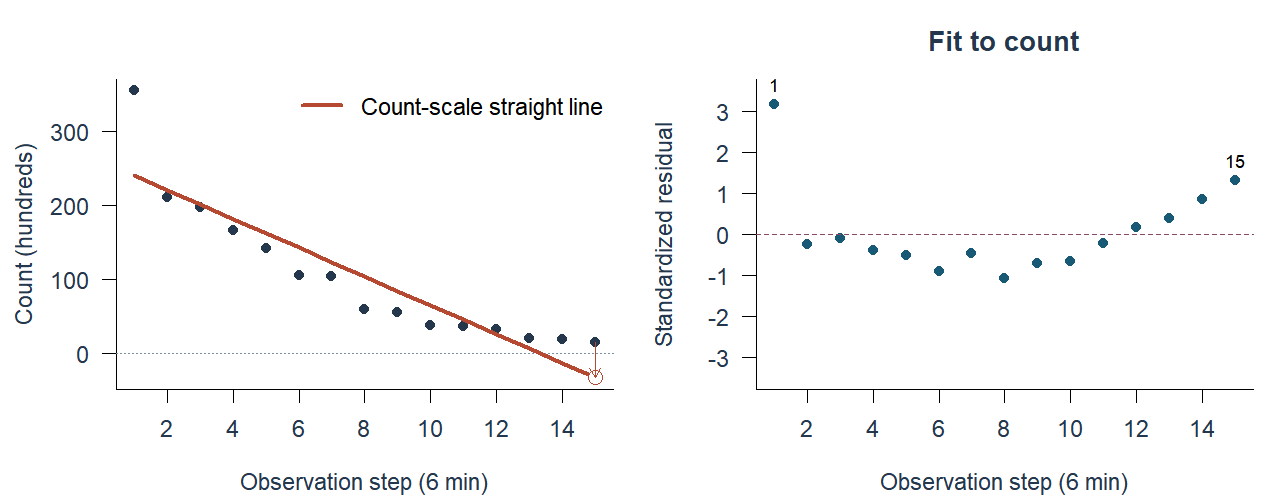

[그림 원본](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/04-raw.png)

In [ ]:
# Data columns: t is the observation index, N_t is in hundreds.
read_bacteria <- function() {
  file_name <- "bacteria-w12a.csv"
  locations <- file.path(c(".", "data", "../data", "labs/student/w12a/data",
                           "../../labs/student/w12a/data", "../../../labs/student/w12a/data"),
                         file_name)
  local <- locations[file.exists(locations)][1L]
  url <- paste0("https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/",
                "labs/student/w12a/data/", file_name)
  d <- read.csv(if (is.na(local)) url else local)
  stopifnot(identical(d$t, 1:15), all(is.finite(d$N_t)), all(d$N_t > 0))
  d
}

plot_decay <- function(d, curves, limit = range(c(d$N_t, unlist(curves)))) {
  plot(d$t, d$N_t, pch = 19, col = "#24374D", ylim = limit,
       xlab = "Observation step (6 min)", ylab = "Count (hundreds)")
  abline(h = 0, lty = 3, col = "#7992A3")
  colors <- c("#B64932", "#087D77")
  for (i in seq_along(curves)) {
    lines(d$t, curves[[i]], col = colors[i], lwd = 3, lty = i)
  }
  legend("topright", names(curves), col = colors[seq_along(curves)],
         lwd = 3, lty = seq_along(curves), bty = "n")
}

plot_decay_residuals <- function(d, fit, title) {
  residual <- rstandard(fit)
  plot(d$t, residual, pch = 19, col = "#185A76",
       xlab = "Observation step (6 min)", ylab = "Standardized residual",
       main = title, ylim = c(-3.5, 3.5))
  abline(h = 0, lty = 2, col = "#8B4961")
  text(d$t[c(1, 15)], residual[c(1, 15)], d$t[c(1, 15)], pos = 3, cex = .8)
}


d <- read_bacteria()
raw <- lm(N_t ~ t, data = d)
print(coef(raw))
print(data.frame(t = d$t, observed = d$N_t, straight = fitted(raw),
                 standardized = rstandard(raw)), row.names = FALSE)
plot_decay_residuals(d, raw, "Count-scale fit")

## B2 · 반응식과 역변환을 편집

현재 결과는 같은 직선 두 개입니다. 아래 함수의 N_t와 inverse를 각각 log(N_t)와 exp로 바꾸고 이 셀부터 다시 실행하세요. fit_on_count_scale이 만든 fitted_count를 그림·표·RMSE가 함께 읽습니다. 행별 제곱오차와 마지막 적합값이 모두 달라지는지 확인하세요.

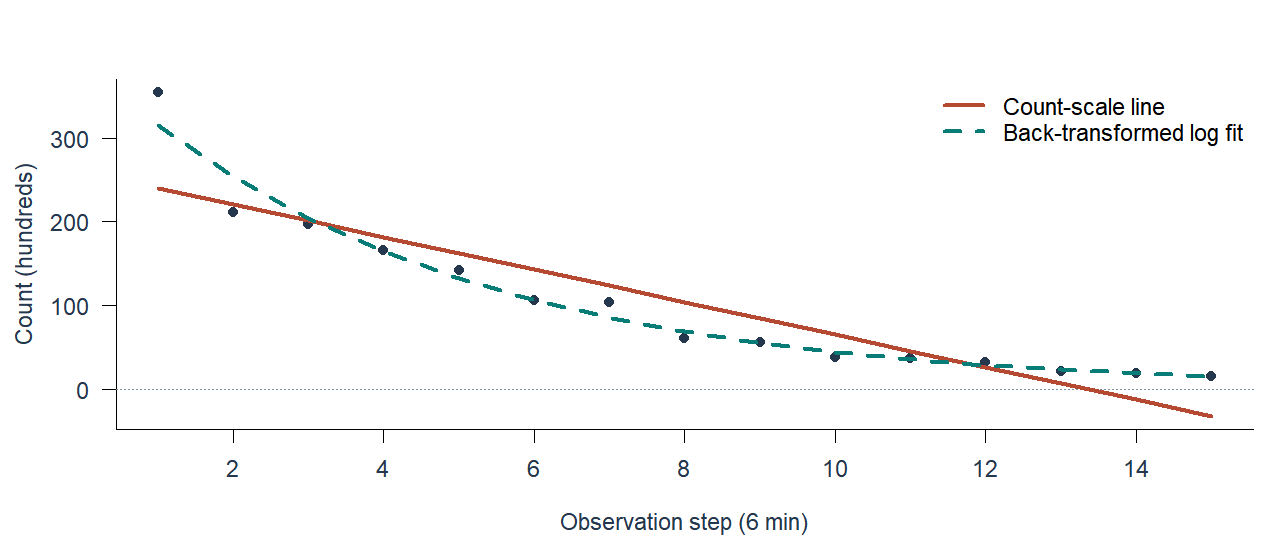

[그림 원본](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/06-overlay.png)

In [ ]:
fit_on_count_scale <- function(d, formula, inverse) {
  fit <- lm(formula, data = d, na.action = na.fail)
  prediction <- inverse(as.numeric(predict(fit, newdata = d)))
  error <- d$N_t - prediction
  rows <- data.frame(t = d$t, observed = d$N_t, fitted_count = prediction,
                     count_error = error, squared_error = error^2,
                     std_residual_fit_scale = as.numeric(rstandard(fit)))
  list(fit = fit, rows = rows, rmse = sqrt(mean(rows$squared_error)))
}


# B2 편집: log(N_t) ~ t로 바꿀 때 inverse도 exp로 바꾸세요.
student_formula <- function() N_t ~ t
student_inverse <- identity


baseline <- fit_on_count_scale(d, N_t ~ t, identity)
tested <- fit_on_count_scale(d, student_formula(), student_inverse)
print(data.frame(model = c("Raw line", "My edited model"),
                 last_fit = c(tail(baseline$rows$fitted_count, 1),
                              tail(tested$rows$fitted_count, 1)),
                 count_rmse = c(baseline$rmse, tested$rmse)))
print(tested$rows, row.names = FALSE)
plot_decay(d, list("Raw count fit" = baseline$rows$fitted_count,
                   "My edited fit" = tested$rows$fitted_count))
plot_decay_residuals(d, tested$fit, "My edited fit")

## B3 · 로그 기울기와 외삽 해석

기울기를 비율로 바꾸어 한 관측 간격의 잔존비와 감소율을 한 문장으로 말하세요. query_t를 0으로 바꾸고 그 값을 관측으로 확인할 수 있는지 답하세요.

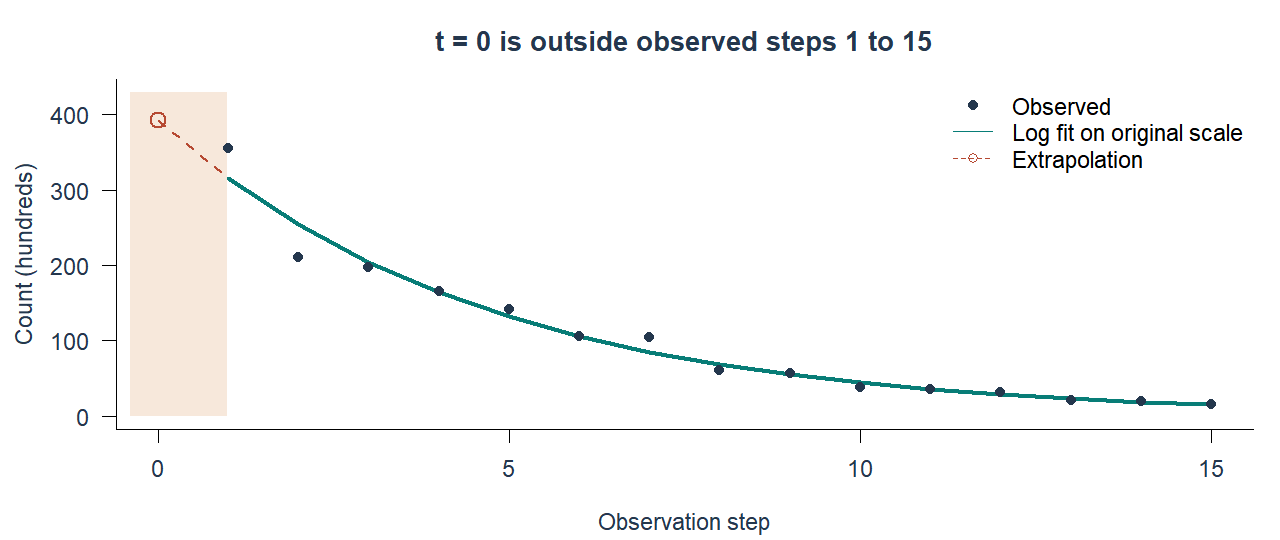

[그림 원본](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w12a/course/notion/w12a/images/07-extrapolation.png)

In [ ]:
log_fit <- lm(log(N_t) ~ t, data = d)
beta <- coef(log_fit)[["t"]]
print(c(ratio_per_6_minutes = exp(beta), percent_drop = 100 * (1 - exp(beta))))
print(exp(confint(log_fit)["t", ]))
# B3 편집: 15를 0으로 바꾸고 관측된 t 범위 안인지 확인합니다.
query_t <- 15
print(data.frame(t = query_t, in_range = query_t >= min(d$t) && query_t <= max(d$t),
                 fitted_count = exp(predict(log_fit, newdata = data.frame(t = query_t)))))

In [ ]:
raw_check <- fit_on_count_scale(d, N_t ~ t, identity)
log_check <- fit_on_count_scale(d, log(N_t) ~ t, exp)
X <- cbind(1, d$t)
qr_log <- qr.coef(qr(X), log(d$N_t))
stopifnot(nrow(d) == 15, abs(raw_check$rmse - 38.94387088) < 1e-6,
          abs(log_check$rmse - 16.35593346) < 1e-6,
          abs(tail(raw_check$rows$fitted_count, 1) + 32.3833333) < 1e-6,
          abs(tail(log_check$rows$fitted_count, 1) - 14.831917) < 1e-6,
          abs(exp(coef(log_check$fit)[2]) - .8037835558) < 1e-8,
          max(abs(qr_log - coef(log_check$fit))) < 1e-10,
          all(sign(raw_check$rows$std_residual_fit_scale) ==
              c(1, rep(-1, 10), rep(1, 4))))
cat("W12A_B_OK\n")